# Tablero descriptivo · Ruta A
Datos BTS/NOAA en HDFS, consulta Spark sobre YARN. Los indicadores son retrospectivos y no representan operaciones LATAM.

In [1]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.appName('TableroOperativoRutaA').master('yarn').getOrCreate()
print('Master:', spark.sparkContext.master, 'Spark:', spark.version)
kpi = spark.read.parquet('hdfs:///proyecto_latam/consumo/kpi_aeropuerto_mes')
print('Aeropuertos-mes:', kpi.count())
kpi.orderBy('anio','mes','origin_code').show(15, truncate=False)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/16 22:49:46 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Master: yarn Spark: 4.0.4


Aeropuertos-mes: 63


+----+---+-----------+------+-------------------+-------------------+--------------------+---------------+
|anio|mes|origin_code|vuelos|vuelos_demorados_15|tasa_demora_15     |demora_media_minutos|cobertura_clima|
+----+---+-----------+------+-------------------+-------------------+--------------------+---------------+
|2026|1  |ATL        |23321 |4914               |0.21071137601303547|13.776381801809528  |1.0            |
|2026|1  |CLT        |12626 |2627               |0.20806272770473627|15.753682876603833  |1.0            |
|2026|1  |DEN        |24008 |4492               |0.18710429856714428|12.430814728423858  |1.0            |
|2026|1  |DFW        |21790 |5791               |0.26576411197797156|21.182973841211567  |1.0            |
|2026|1  |LAS        |13423 |2681               |0.19973180362065113|13.578484690456678  |1.0            |
|2026|1  |LAX        |14460 |2791               |0.193015214384509  |15.906016597510373  |1.0            |
|2026|1  |MCO        |13232 |3353    

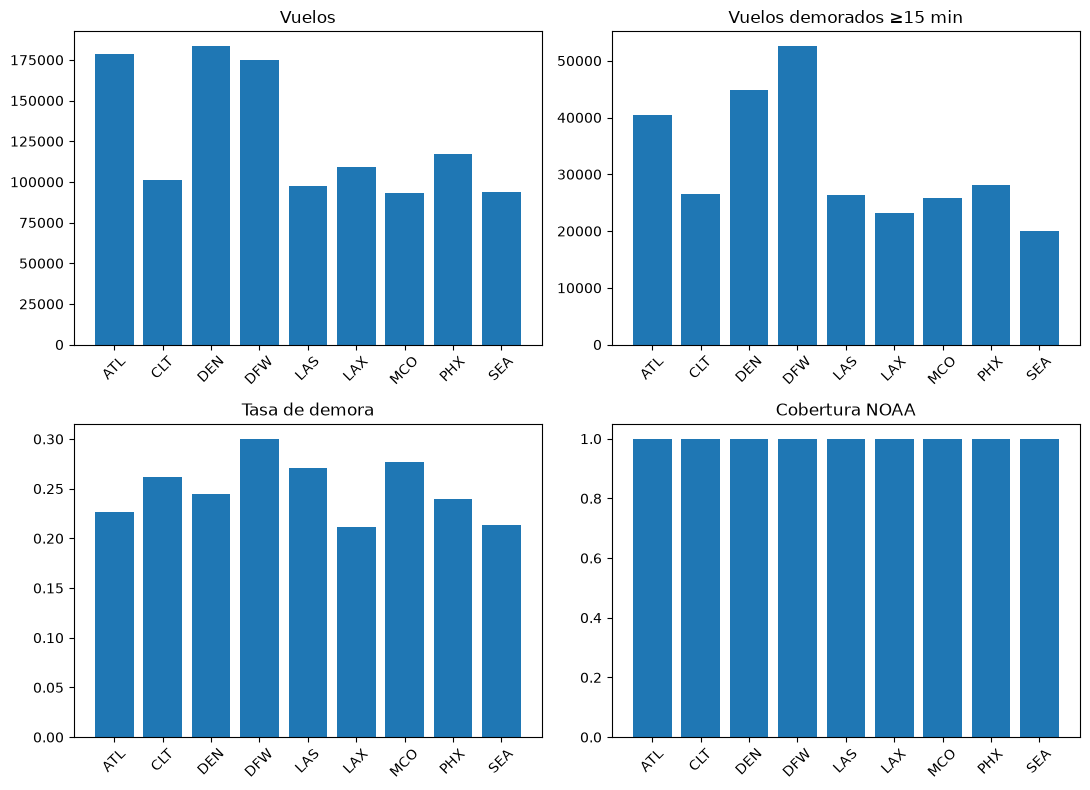

In [2]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
tabla = (kpi.groupBy('origin_code')
         .agg(F.sum('vuelos').alias('vuelos'), F.sum('vuelos_demorados_15').alias('demorados'),
              (F.sum(F.col('cobertura_clima') * F.col('vuelos')) / F.sum('vuelos')).alias('cobertura'))
         .withColumn('tasa', F.col('demorados') / F.col('vuelos'))
         .orderBy('origin_code').toPandas())
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, campo, titulo in zip(axes.flat, ['vuelos','demorados','tasa','cobertura'],
                             ['Vuelos', 'Vuelos demorados ≥15 min', 'Tasa de demora', 'Cobertura NOAA']):
    ax.bar(tabla['origin_code'], tabla[campo])
    ax.set_title(titulo)
    ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

**Interpretación:** comparar aeropuertos con tasas y volumen; las cifras concretas deben redactarse después de ejecutar esta notebook. Responsable propuesto: analista de operaciones. Frecuencia: mensual tras actualizar las fuentes.

In [3]:
spark.stop()